In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# kagglehub.dataset_download('<owner>/<dataset-slug>')

**I'm using a dataset consist of students' Sleep time and screen time per week and how these features infuence his ultimate Cgpa**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#Loading Data...
df = pd.read_csv('/content/drive/MyDrive/Books pdf/student_sleep_screen_time_academic_performance.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Data loading completed. Let's see first 10 rows**


In [ ]:
#Let's see some of the dataset
df.head(10)

,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74
5,STU2006,19,Female,3,Health Sciences,Dormitory,Intermediate,0.6,9.0,1.2,...,0,8.0,2,7.0,3.0,17.0,100.0,No,Spring,2.88
6,STU2007,19,Female,2,Social Sciences,With Family,Intermediate,22.4,5.7,3.7,...,1,6.0,1,5.0,8.0,9.9,60.4,Yes,Summer,2.60
7,STU2008,21,Female,3,Humanities,Off-campus Apartment,Night Owl,1.5,4.0,3.8,...,3,6.0,2,5.0,10.0,14.5,69.5,No,Spring,2.62
8,STU2009,17,Female,3,Social Sciences,Off-campus Apartment,Early Bird,21.4,7.6,0.9,...,1,9.0,1,10.0,8.0,16.1,85.2,Yes,Spring,NaN
9,STU2010,17,Male,4,STEM,Dormitory,Intermediate,23.5,5.6,1.0,...,2,10.0,6,8.0,4.0,15.6,80.1,Yes,Fall,2.85


**Let's figure out some many samples does it have and is it enough or not**

In [ ]:
#Let's see how much big this dataset is!
Samples , features = df.shape

print(f"This dataset has ---- {Samples} Samples")


This dataset has ---- 500 Samples


****

**Now let's see how many features does it have and is it enough or not?**

In [ ]:
#Let's see how many features it has

Columns_name =list(df.columns)

#student_id and cgpa is not included in the feature

print(f"\nTotal features are {len(Columns_name)-2}")


Total features are 23


**Let's see what are the data types does it consist of and which column have what type of data**

In [ ]:
#Let's see how many types of data it has and which columns have what type of data

Numerical_Col = list(df.select_dtypes(exclude = ["object"]).columns)
Categorical_Col = list(df.select_dtypes(include = ["object"]).columns)

print(df.dtypes)


print("\nQuantative data columns are--->\n")
for i, x in enumerate(Numerical_Col):
    print(i+1, x)
print(f"\nTotal {len(Numerical_Col)}")

print("\n\nQualatitive data columns are--->\n")
for i, x in enumerate(Categorical_Col):
    print(i+1, x)
print(f"\nTotal {len(Categorical_Col)}")




student_id                    object
age                            int64
gender                        object
year_of_study                  int64
major_category                object
residence_type                object
chronotype                    object
avg_bedtime_hour             float64
avg_sleep_hours_weekday      float64
weekend_sleep_delta_hours    float64
pre_sleep_screen_time_min      int64
daily_screen_time_hours      float64
primary_device                object
device_free_before_bed        object
caffeine_drinks_per_day        int64
naps_per_week                  int64
sleep_quality_score          float64
exercise_days_per_week         int64
energy_level                 float64
concentration_difficulty     float64
weekly_study_hours           float64
class_attendance_percent     float64
has_part_time_job             object
semester_type                 object
cgpa                         float64
dtype: object

Quantative data columns are--->

1 age
2 year_of_study
3 avg

**Below there are columns which have null values and they mentioned indiviually. Afterward, there are the row numbers which carrying those null values are also mentioned**

In [ ]:
#Let's see how many columns have null values

print("These columns have null values of these numbers:\n")
print(df.isnull().sum()[df.isnull().sum() > 0])

#Let's see which rows have null values
print("\nThese rows have null values:")
print(df[df.isnull().any(axis=1)].index.tolist())

These columns have null values of these numbers:

device_free_before_bed       9
sleep_quality_score          6
energy_level                15
concentration_difficulty    14
cgpa                         7
dtype: int64

These rows have null values:
[6, 8, 11, 13, 21, 30, 59, 76, 89, 98, 102, 118, 119, 131, 132, 137, 155, 160, 172, 179, 191, 196, 198, 212, 242, 243, 276, 282, 295, 297, 311, 338, 359, 361, 381, 391, 398, 417, 421, 426, 454, 477, 482, 499]


**Here it has been specified that which columns are the features and which one is our target**

In [ ]:
#Let's specify the feature columns and our target output column

print("These Columns are the features: \n")

features = df.iloc[:,1:24]
for i, x in enumerate(features):
    print(i+1, x)

print("\nThe target column is : 'cgpa'\n")

These Columns are the features: 

1 age
2 gender
3 year_of_study
4 major_category
5 residence_type
6 chronotype
7 avg_bedtime_hour
8 avg_sleep_hours_weekday
9 weekend_sleep_delta_hours
10 pre_sleep_screen_time_min
11 daily_screen_time_hours
12 primary_device
13 device_free_before_bed
14 caffeine_drinks_per_day
15 naps_per_week
16 sleep_quality_score
17 exercise_days_per_week
18 energy_level
19 concentration_difficulty
20 weekly_study_hours
21 class_attendance_percent
22 has_part_time_job
23 semester_type

The target column is : 'cgpa'



**The ultimate question is that whether Semester_type really have any influence in student's Cgps score if it has then how much**

**To get the answer, we have to visualize these data whether the semester type have influence in cgpa or not**

semester_type
Fall      2.825830
Spring    2.855528
Summer    2.798169
Name: cgpa, dtype: float64


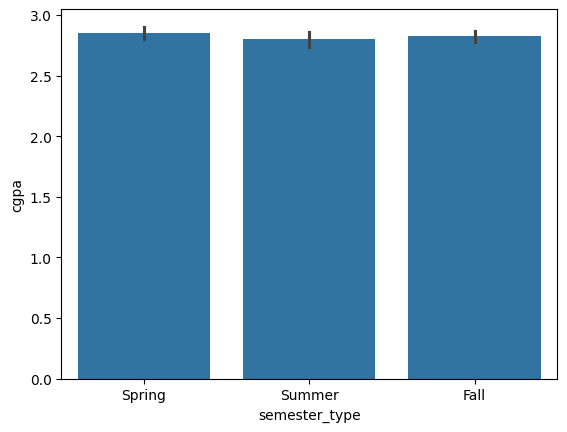

In [ ]:
print(df.groupby("semester_type")["cgpa"].mean())
sns.barplot(data=df, x="semester_type", y="cgpa")
plt.show()

**After visualizing the graph, it is clear that students' cgpas are arround same regardless of semester type. So, it could be concluded that semester type actually have no influence on students' cgps**